# 기능 F 굿즈 목업: F1 합성 매핑 보강 비교 (11/02)

21 상세 페이지에서 F0(SDXL img2img + IP-Adapter)이 굿즈에 그림을 거의 찍지 못하는 문제가 확인됐다(14 `design_sim` F0s0.45 0.530, F1 0.941). F를 F1 합성으로 바꾸기 전에, F1 결과가 스티커처럼 보이는 문제를 매핑을 더해 줄일 수 있는지 비교한다. GPU 생성 모델은 쓰지 않고 이미지 처리만 한다(지표의 CLIP만 GPU가 있으면 GPU에서 돈다).

| 후보 | 내용 | 대상 |
|---|---|---|
| F1 | 14 F1 그대로: 원통 반각 60°(머그), 밝기 변위(인쇄 영역 너비의 2%), 곱하기 음영 `1 - (1 - shade) × 0.6` | 전체 |
| F1curve | + 위아래 휨: 위에서 내려다본 머그는 몸통 가운데가 가장자리보다 아래로 내려와 보인다. 굿즈 마스크의 몸통 아래 윤곽에 타원 `y = y0 + b·√(1 - u²)`를 맞춰 사진마다 휨 크기 b를 재고, 그림의 열마다 그만큼 내린다 | 머그 |
| F1spec | + 반사광: 원본 사진에서 주변보다 밝은 부분(회색조 − 큰 흐림)을 그림 위에 스크린 방식으로 다시 얹는다 | 머그 |
| F1cloth | + 천 질감: 변위를 2배로 키우고, 원본의 잔결(회색조 − 작은 흐림)을 그림에 더한다 | 티셔츠·후드·에코백 |

- 인쇄 영역: 14 규칙은 굿즈 마스크의 경계 상자 기준인데, 마스크에 손잡이·옷걸이·옆에 걸린 청바지(hoodie_01)·옷걸이 봉과 손(hoodie_02)까지 들어가 영역이 어긋났다(11/02 사용자 확인: 에코백은 입구 쪽, tshirt_02는 목둘레, 후드는 모자·끈과 청바지 위). 그래서 머그를 뺀 굿즈는 몸통만 다시 찾아 잡는다. 기준 F1도 새 영역으로 만든다.
  - 머그: 14 `print_boxes.csv` 그대로. 단 mug_04는 머그 두 개가 나란히 있는 사진이라 14 영역이 두 머그 사이에 걸렸으므로(11/02 확인), 사용자 결정대로 왼쪽 머그의 몸통 열만으로 14 머그 규칙(몸통 너비의 60%, 몸통 세로 가운데, 최대 높이 45%)을 다시 적용한다(`MUG_SIDE`).
  - 에코백: 가로로 넓게 채워진 행(가장 넓은 행의 60% 이상)만 몸통으로 보고, 몸통 너비의 55%로 세로 가운데에 둔다.
  - 티셔츠·후드: 마스크를 긴 변 256으로 줄여 경계에서의 거리(깎아 낸 횟수)를 구하고, 가장 깊은 점(몸통 가운데)에서 깊이 50% 이상인 덩어리만 남긴 뒤 같은 만큼 되살린다. 소매·옷걸이·청바지처럼 몸통보다 가는 부분이 빠진다. 가로 가운데는 가장 깊은 점, 몸통 너비는 깊이 × 2로 본다(몸통 덩어리에 청바지 일부가 붙어 남아도 영향받지 않게, 11/02 hoodie_01이 오른쪽으로 치우친 것을 사용자 확인). 너비의 55%(후드 60%)로 몸통 위에서 20%(후드는 모자가 몸통에 포함돼 25%) 아래에 둔다.
- 입력
  - 굿즈: 14와 같은 무지 굿즈 사진 11장(긴 변 1024)과 14 BiRefNet 마스크(`outputs/mockup_f/masks/`)
  - 그림: 14와 같은 12 결과 3장(냥기사 B0, KayKit B2, 0x72 B4)
- 규모: F1 33장, F1curve·F1spec 각 머그 4장 × 그림 3장, F1cloth 7장 × 그림 3장. 대상이 아닌 굿즈는 F1과 같으므로 만들지 않는다.
- 확인: "합성 함수·14 F1 재현 확인" 셀에서 14 인쇄 영역으로 F1을 다시 만들어 14 결과 파일과 픽셀 차이가 0인지 본다.
- 지표 (14와 같은 정의)
  - `keep_ssim`·`keep_psnr`: 인쇄 영역(F1curve는 내려간 만큼 넓힌 영역)을 16px 넓힌 영역 밖에서 원본 대비
  - `design_sim`: 인쇄 영역을 잘라 낸 이미지와 그림의 CLIP 유사도
  - 장당 시간, 육안 비교 그림(인쇄 영역 확대)
- 탐색값(근거 문서 없음): 반사광 흐림 반경(인쇄 영역 너비의 8%), 반사광 범위 30 회색조, 반사광 세기 0.9, 천 변위 배수 2, 잔결 흐림 반경 2px, 잔결 세기 1.5, 에코백 몸통 행 기준(가장 넓은 행의 60%), 옷 몸통 깊이 기준 50%, 옷 인쇄 영역 너비·위치 비율, 휨 맞춤 범위(몸통 가운데 80%)
- 기록 (`outputs/mockup_f1map/`)
  - `f1m_config.json`, `print_boxes_22.csv`, `print_boxes_22.png`, `mug_curve.csv`, `mug_curve.png`, `repro_14.csv`
  - `f1m_records.csv`: 이미지마다 방식·굿즈·그림·인쇄 영역·설정·시간·오류(건너뛴 이유)
  - `f1m_scored.csv`, `f1m_summary.csv`, `f1m_scores.png`, `f1m_zoom_<그림>.png`
- 실행 순서: 위에서부터 차례로. 다시 실행하면 설정이 같고 오류 없이 만든 이미지는 건너뛴다.
- 예상 시간: 합성 78장 × 약 0.3초(14 F1 장당 0.336초) + CLIP 로드·지표 약 1분

## 설정

In [1]:
import importlib.metadata
import json
import platform
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter

ROOT = Path('..')
OUT_DIR = ROOT / 'outputs' / 'mockup_f1map'
OUT_DIR.mkdir(parents=True, exist_ok=True)
F14_DIR = ROOT / 'outputs' / 'mockup_f'
MASK_DIR = F14_DIR / 'masks'
assert (F14_DIR / 'print_boxes.csv').exists() and MASK_DIR.exists(), '14 결과가 없음 → 14 "굿즈 마스크·인쇄 영역" 셀을 먼저 실행'
REC_CSV = OUT_DIR / 'f1m_records.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
SRC_CSV = GOODS_DIR / 'goods_sources.csv'
assert SRC_CSV.exists(), '굿즈 사진이 없음 → 03 "4-1. 무료 사진 사이트에서 무지 굿즈 사진 받기" 셀을 먼저 실행'
GOODS = pd.read_csv(SRC_CSV, keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
assert len(GOODS), '받은 굿즈 사진이 없음'
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 원본 사진은 4000px 이상이라 긴 변 1024(8의 배수)로 줄여 모든 방식에 같은 입력으로 씀
MAX_SIDE = 1024


def load_goods(name):
    im = Image.open(GOODS_DIR / name).convert('RGB')
    s = MAX_SIDE / max(im.size)
    w, h = (int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8)
    return im.resize((w, h), Image.LANCZOS)


print('굿즈', len(GOODS), '장:', GOODS.groupby('kind').size().to_dict())

C_DIR = ROOT / 'outputs' / 'promo_c'
DESIGNS = {'nai': C_DIR / 'C_B0_nai_ipa_s0.png', 'kaykit': C_DIR / 'C_B2_kaykit_ipa_s0.png', 'x72': C_DIR / 'C_B4_x72_ipa_s0.png'}
assert all(p.exists() for p in DESIGNS.values()), '12 노트북 결과가 없음'
KIND = dict(zip(GOODS.file, GOODS.kind))
FABRIC = ['tshirt', 'hoodie', 'tote']

# 14 F1과 같은 값
DISP_RATIO = 0.02
SHADE_BLEND = 0.6
MUG_HALF_ANGLE = np.deg2rad(60)
# 탐색값
SPEC_SIGMA_RATIO, SPEC_RANGE, SPEC_BLEND = 0.08, 30.0, 0.9
CLOTH_DISP_MULT, CLOTH_DETAIL_SIGMA, CLOTH_DETAIL = 2.0, 2.0, 1.5
TOTE_ROW_RATIO = 0.6
TORSO_SMALL, TORSO_CORE_RATIO = 256, 0.5
# 머그 두 개가 나란히 있는 사진은 한쪽 머그에만 인쇄 (11/02 사용자 결정: mug_04는 왼쪽)
MUG_SIDE = {'mug_04.jpg': 'left'}
# 14 BOX_RULE 머그 (너비 비율, 최대 높이 비율)
MUG_WR, MUG_HMAX = 0.60, 0.45
# 옷 인쇄 영역: (몸통 너비 비율, 몸통 위에서 내려올 비율, 최대 높이 비율)
GARMENT_RULE = {'tshirt': (0.55, 0.20, 0.35), 'hoodie': (0.60, 0.25, 0.35)}
CURVE_FIT_RANGE = 0.8

# 후보: (대상 종류, 켤 매핑)
CANDIDATES = {'F1': (['mug'] + FABRIC, {}), 'F1curve': (['mug'], dict(curve=True)),
              'F1spec': (['mug'], dict(spec=True)), 'F1cloth': (FABRIC, dict(cloth=True))}


def load_mask(name):
    return np.asarray(Image.open(MASK_DIR / f'{Path(name).stem}.png')).astype(np.float32) / 255.0


print('그림', list(DESIGNS), '| 후보', {m: len(GOODS[GOODS.kind.isin(k)]) * len(DESIGNS) for m, (k, _) in CANDIDATES.items()})

def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


def append_csv(path, rec):
    pd.DataFrame([rec]).to_csv(path, mode='a', header=not path.exists(), index=False, encoding='utf-8-sig')

굿즈 11 장: {'hoodie': 2, 'mug': 4, 'tote': 3, 'tshirt': 2}
그림 ['nai', 'kaykit', 'x72'] | 후보 {'F1': 33, 'F1curve': 12, 'F1spec': 12, 'F1cloth': 21}


## 인쇄 영역 (에코백은 몸통 기준으로 다시 잡음)

,file,kind,x,y,w,h,source,body_y0,body_y1
0,mug_01.jpg,mug,388,555,210,143,14 print_boxes.csv,NaN,NaN
1,mug_02.jpg,mug,435,276,187,128,14 print_boxes.csv,NaN,NaN
2,mug_03.jpg,mug,189,411,154,105,14 print_boxes.csv,NaN,NaN
3,mug_04.jpg,mug,278,327,127,87,left mug body (2 mugs),229.0,513.0
4,tshirt_01.jpg,tshirt,420,192,176,120,torso (depth core),92.0,595.0
5,tshirt_02.jpg,tshirt,426,237,171,117,torso (depth core),140.0,627.0
6,tote_01.jpg,tote,410,344,213,146,tote body rows,207.0,627.0
7,tote_02.jpg,tote,227,587,217,148,tote body rows,469.0,854.0
8,tote_03.jpg,tote,254,666,143,97,tote body rows,574.0,856.0
9,hoodie_01.jpg,hoodie,431,314,201,137,torso (depth core),192.0,679.0


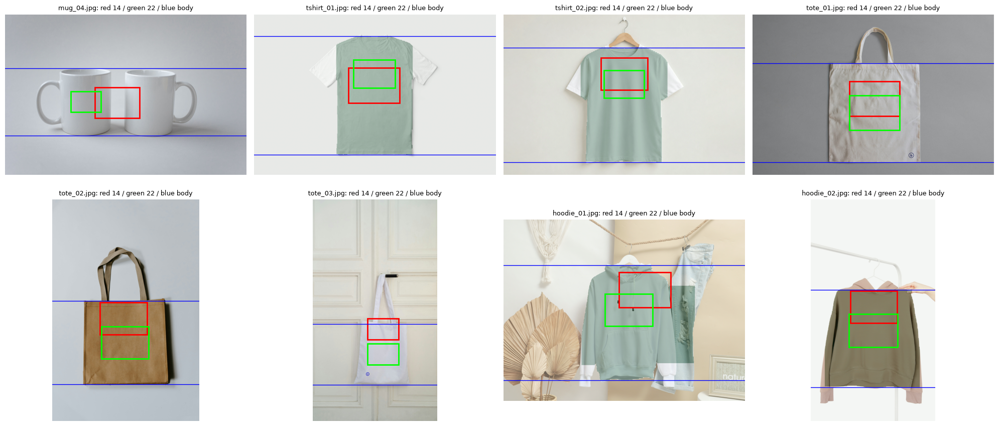

In [2]:
b14 = pd.read_csv(F14_DIR / 'print_boxes.csv', keep_default_na=False)
BOX14 = {r.file: (int(r.x), int(r.y), int(r.w), int(r.h)) for r in b14.itertuples()}
ASPECT = Image.open(DESIGNS['nai']).width / Image.open(DESIGNS['nai']).height
# 14 에코백 비율 (너비 비율, 최대 높이 비율)을 몸통 기준으로 씀
TOTE_WR, TOTE_HMAX = 0.55, 0.45


def tote_box(name):
    m = load_mask(name) > 0.5
    rows = m.sum(1)
    # 손잡이 행은 폭이 좁으므로 가장 넓은 행의 60% 이상인 행만 몸통으로 봄
    body = np.nonzero(rows >= TOTE_ROW_RATIO * rows.max())[0]
    y0, y1 = body.min(), body.max()
    sub = m[y0:y1 + 1]
    xs = np.nonzero(sub.any(0))[0]
    bw, bh = xs.max() - xs.min() + 1, y1 - y0 + 1
    cx = np.median(np.nonzero(sub)[1])
    w = TOTE_WR * bw
    h = w / ASPECT
    if h > TOTE_HMAX * bh:
        h = TOTE_HMAX * bh
        w = h * ASPECT
    return int(cx - w / 2), int(y0 + (bh - h) / 2), int(w), int(h), int(y0), int(y1)


def torso_mask(name):
    m = load_mask(name) > 0.5
    H, W = m.shape
    s = TORSO_SMALL / max(H, W)
    cur = Image.fromarray((m * 255).astype(np.uint8)).resize((max(1, round(W * s)), max(1, round(H * s))), Image.NEAREST)
    small = np.asarray(cur) > 127
    # 3×3로 깎아 낸 횟수 = 경계에서의 거리
    depth = np.zeros(small.shape, np.int32)
    while (np.asarray(cur) > 127).any():
        depth += np.asarray(cur) > 127
        cur = cur.filter(ImageFilter.MinFilter(3))
    maxd = int(depth.max())
    ys, xs = np.nonzero(depth == maxd)
    i = np.argsort(xs)[len(xs) // 2]
    kd = int(round(TORSO_CORE_RATIO * maxd))
    # fromarray 이미지는 배열 메모리를 공유해 floodfill이 반영되지 않으므로 copy
    core = Image.fromarray(((depth >= kd) * 128).astype(np.uint8)).copy()
    ImageDraw.floodfill(core, (int(xs[i]), int(ys[i])), 255)
    comp = Image.fromarray(((np.asarray(core) == 255) * 255).astype(np.uint8))
    for _ in range(kd):
        comp = comp.filter(ImageFilter.MaxFilter(3))
    t = (np.asarray(comp) > 127) & small
    big = (np.asarray(Image.fromarray((t * 255).astype(np.uint8)).resize((W, H), Image.NEAREST)) > 127) & m
    # 가장 깊은 점 = 몸통 가운데, 깊이 × 2 = 몸통 안쪽 너비 (몸통에 붙어 남은 청바지·손에 영향받지 않음)
    return big, float(xs[i] / s), 2 * maxd / s


def garment_box(name, kind):
    t, cx, tw = torso_mask(name)
    TORSO[name] = t
    ys = np.nonzero(t.any(1))[0]
    y0, y1 = ys.min(), ys.max()
    th = y1 - y0 + 1
    wr, top, hmax = GARMENT_RULE[kind]
    w = wr * tw
    h = w / ASPECT
    if h > hmax * th:
        h = hmax * th
        w = h * ASPECT
    return int(cx - w / 2), int(y0 + top * th), int(w), int(h), int(y0), int(y1)


def mug_box_side(name, side):
    m = load_mask(name) > 0.5
    ys, xs = np.nonzero(m)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    body = m[y0:y1 + 1, x0:x1 + 1].sum(0)
    body = body >= 0.6 * body.max()
    runs, i = [], 0
    while i < len(body):
        if body[i]:
            j = i
            while j + 1 < len(body) and body[j + 1]:
                j += 1
            runs.append((i + x0, j + x0))
            i = j + 1
        else:
            i += 1
    l, r = runs[0] if side == 'left' else runs[-1]
    rows_ = np.nonzero(m[:, l:r + 1].any(1))[0]
    by0, bh = rows_.min(), rows_.max() - rows_.min() + 1
    w = MUG_WR * (r - l + 1)
    h = w / ASPECT
    if h > MUG_HMAX * bh:
        h = MUG_HMAX * bh
        w = h * ASPECT
    return int((l + r) / 2 - w / 2), int(by0 + (bh - h) / 2), int(w), int(h), int(by0), int(by0 + bh - 1), len(runs)


TORSO = {}
rows = []
for g in GOODS.itertuples():
    if g.kind == 'tote':
        x, y, w, h, y0, y1 = tote_box(g.file)
        rows.append(dict(file=g.file, kind=g.kind, x=x, y=y, w=w, h=h, source='tote body rows', body_y0=y0, body_y1=y1))
    elif g.file in MUG_SIDE:
        x, y, w, h, y0, y1, n_runs = mug_box_side(g.file, MUG_SIDE[g.file])
        rows.append(dict(file=g.file, kind=g.kind, x=x, y=y, w=w, h=h, source=f'{MUG_SIDE[g.file]} mug body ({n_runs} mugs)',
                         body_y0=y0, body_y1=y1))
    elif g.kind in GARMENT_RULE:
        x, y, w, h, y0, y1 = garment_box(g.file, g.kind)
        rows.append(dict(file=g.file, kind=g.kind, x=x, y=y, w=w, h=h, source='torso (depth core)', body_y0=y0, body_y1=y1))
    else:
        rows.append(dict(file=g.file, kind=g.kind, **dict(zip('xywh', BOX14[g.file])), source='14 print_boxes.csv'))
boxes = pd.DataFrame(rows)
boxes.to_csv(OUT_DIR / 'print_boxes_22.csv', index=False, encoding='utf-8-sig')
BOX = {r.file: (int(r.x), int(r.y), int(r.w), int(r.h)) for r in boxes.itertuples()}
display(boxes)

changed = boxes[boxes.source != '14 print_boxes.csv']
fig, axes = plt.subplots(2, int(np.ceil(len(changed) / 2)), figsize=(5 * int(np.ceil(len(changed) / 2)), 9), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, r in zip(axes.flat, changed.itertuples()):
    ax.imshow(load_goods(r.file))
    if r.file in TORSO:
        ax.imshow(TORSO[r.file], alpha=0.3, cmap='Greens')
    for (x, y, w, h), c, lab in [(BOX14[r.file], 'red', '14'), (BOX[r.file], 'lime', '22')]:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color=c, lw=2, label=lab))
    for yb in (r.body_y0, r.body_y1):
        ax.axhline(yb, color='blue', lw=1)
    ax.set_title(f'{r.file}: red 14 / green 22 / blue body', fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / 'print_boxes_22.png', dpi=60)
plt.show()

## 머그 몸통 휨 측정 (F1curve용)

,file,ok,reason,cx,half,b,y0,fit_rmse
0,mug_01.jpg,True,,493.5,175.0,63.30,801.66,0.35
1,mug_02.jpg,True,,529.5,156.0,54.93,516.67,0.52
2,mug_03.jpg,True,,266.5,129.0,41.16,550.40,1.10
3,mug_04.jpg,True,,342.0,106.5,37.76,475.57,1.00


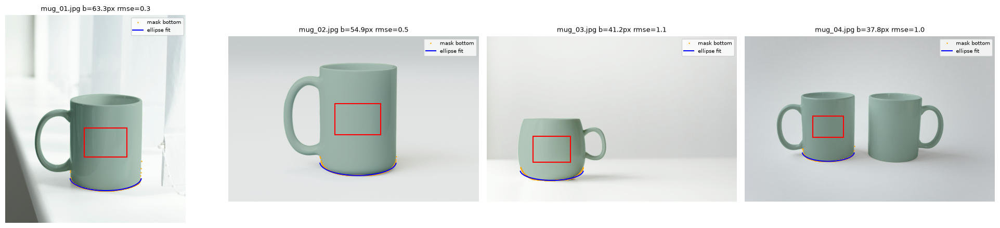

In [3]:
def mug_curve(name):
    m = load_mask(name) > 0.5
    x, y, w, h = BOX[name]
    ys, xs = np.nonzero(m)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    col = m[y0:y1 + 1, x0:x1 + 1].sum(0)
    # 14 인쇄 영역과 같은 기준: 세로로 많이 채워진 열이 몸통(손잡이 제외)
    body = col >= 0.6 * col.max()
    c = int(x + w / 2) - x0
    if not body[c]:
        return dict(file=name, ok=False, reason='인쇄 영역 가운데가 몸통 열이 아님', reason_en='box center not on body column')
    l, r = c, c
    while l > 0 and body[l - 1]:
        l -= 1
    while r < len(body) - 1 and body[r + 1]:
        r += 1
    cols = np.arange(l, r + 1) + x0
    bottom = np.array([np.nonzero(m[:, cx])[0].max() for cx in cols], dtype=float)
    cx, half = (cols[0] + cols[-1]) / 2, (cols[-1] - cols[0] + 1) / 2
    u = (cols - cx) / half
    # 몸통 양 끝은 마스크 경계가 흐려 가운데 80%만 맞춤
    sel = np.abs(u) <= CURVE_FIT_RANGE
    A = np.stack([np.ones(sel.sum()), np.sqrt(1 - u[sel] ** 2)], 1)
    (yb, b), *_ = np.linalg.lstsq(A, bottom[sel], rcond=None)
    rmse = float(np.sqrt(np.mean((A @ np.array([yb, b]) - bottom[sel]) ** 2)))
    return dict(file=name, ok=True, reason='', reason_en='', cx=float(cx), half=float(half), b=float(b), y0=float(yb), fit_rmse=rmse,
                cols=cols, bottom=bottom)


CURVES = {n: mug_curve(n) for n in GOODS.file[GOODS.kind == 'mug']}
curve_tab = pd.DataFrame([{k: v for k, v in c.items() if k not in ('cols', 'bottom')} for c in CURVES.values()])
curve_tab.to_csv(OUT_DIR / 'mug_curve.csv', index=False, encoding='utf-8-sig')
display(curve_tab.drop(columns='reason_en').round(2))

fig, axes = plt.subplots(1, len(CURVES), figsize=(5 * len(CURVES), 4.5), squeeze=False)
for ax, (n, c) in zip(axes[0], CURVES.items()):
    ax.imshow(load_goods(n))
    ax.imshow(load_mask(n), alpha=0.3, cmap='Greens')
    x, y, w, h = BOX[n]
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color='red', lw=1.5))
    if c['ok']:
        u = (c['cols'] - c['cx']) / c['half']
        ax.plot(c['cols'], c['bottom'], '.', ms=1.5, color='orange', label='mask bottom')
        ax.plot(c['cols'], c['y0'] + c['b'] * np.sqrt(np.clip(1 - u ** 2, 0, 1)), color='blue', lw=1.5, label='ellipse fit')
        ax.legend(fontsize=7)
        ax.set_title(f"{n} b={c['b']:.1f}px rmse={c['fit_rmse']:.1f}", fontsize=9)
    else:
        ax.set_title(f"{n} skipped: {c['reason_en']}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'mug_curve.png', dpi=60)
plt.show()

## 합성 함수·14 F1 재현 확인

In [4]:
def bilinear(img, yy, xx):
    h, w = img.shape[:2]
    yy, xx = np.clip(yy, 0, h - 1), np.clip(xx, 0, w - 1)
    y0, x0 = np.floor(yy).astype(int), np.floor(xx).astype(int)
    y1, x1 = np.minimum(y0 + 1, h - 1), np.minimum(x0 + 1, w - 1)
    wy, wx = (yy - y0)[..., None], (xx - x0)[..., None]
    return (img[y0, x0] * (1 - wy) * (1 - wx) + img[y0, x1] * (1 - wy) * wx + img[y1, x0] * wy * (1 - wx) + img[y1, x1] * wy * wx)


def compose(name, design_path, box, curve=False, spec=False, cloth=False):
    # 반환: (합성 이미지, 실제로 그린 높이). F1curve는 가운데가 내려간 만큼 영역이 아래로 늘어남
    img = load_goods(name)
    kind = KIND[name]
    x, y, w, h = box
    d = np.asarray(Image.open(design_path).convert('RGB').resize((w, h), Image.LANCZOS), dtype=np.float64)
    lift, H = None, h
    if curve:
        c = CURVES[name]
        us = np.clip((x + np.arange(w) + 0.5 - c['cx']) / c['half'], -1, 1)
        lift = c['b'] * np.sqrt(1 - us ** 2)
        lift = lift - lift.min()
        H = min(h + int(np.ceil(lift.max())), img.height - y)
    yy, xx = np.mgrid[0:H, 0:w].astype(np.float64)
    if kind == 'mug':
        # 원통 곡면: 화면 가로 위치 u → 그림 가로 위치 θ/θmax (가장자리일수록 눌림)
        u = (xx + 0.5) / w * 2 - 1
        xx = (np.arcsin(np.clip(u, -1, 1) * np.sin(MUG_HALF_ANGLE)) / MUG_HALF_ANGLE + 1) / 2 * w - 0.5
    if lift is not None:
        yy = yy - lift[None, :]
    gray_l = img.convert('L')
    gray_raw = np.asarray(gray_l, dtype=np.float64)[y:y + H, x:x + w]
    gray = np.asarray(gray_l.filter(ImageFilter.GaussianBlur(2)), dtype=np.float64)[y:y + H, x:x + w]
    region = load_mask(name)[y:y + H, x:x + w]
    inside = gray[region > 0.5] if (region > 0.5).any() else gray.ravel()
    lo, hi = np.percentile(inside, 2), np.percentile(inside, 98)
    ln = np.clip((gray - lo) / max(hi - lo, 1e-6), 0, 1)
    disp = (ln - 0.5) * DISP_RATIO * (CLOTH_DISP_MULT if cloth else 1) * w
    sy, sx = yy + disp, xx + disp
    # 휨으로 그림 밖을 가리키는 픽셀은 원본을 그대로 둠
    valid = ((sy >= -0.5) & (sy <= h - 0.5)).astype(np.float64) if lift is not None else 1.0
    warped = bilinear(d, sy, sx)
    shade = np.clip(gray / max(np.percentile(inside, 95), 1e-6), 0, 1)
    warped = warped * (1 - (1 - shade) * SHADE_BLEND)[..., None]
    if cloth:
        g = Image.fromarray(gray_raw.clip(0, 255).astype(np.uint8))
        detail = gray_raw - np.asarray(g.filter(ImageFilter.GaussianBlur(CLOTH_DETAIL_SIGMA)), dtype=np.float64)
        warped = warped + (detail * CLOTH_DETAIL)[..., None]
    if spec:
        # 큰 흐림보다 밝은 좁은 띠만 반사광으로 봄 (넓은 밝기 변화는 음영이 이미 반영)
        blur = np.asarray(gray_l.filter(ImageFilter.GaussianBlur(SPEC_SIGMA_RATIO * w)), dtype=np.float64)[y:y + H, x:x + w]
        hl = np.clip((gray - blur) / SPEC_RANGE, 0, 1)
        warped = warped + (255 - warped) * (hl * SPEC_BLEND)[..., None]
    a = np.asarray(img, dtype=np.float64).copy()
    alpha = (region * valid)[..., None]
    a[y:y + H, x:x + w] = a[y:y + H, x:x + w] * (1 - alpha) + warped.clip(0, 255) * alpha
    return Image.fromarray(a.clip(0, 255).astype(np.uint8)), H


# 14 인쇄 영역으로 F1을 다시 만들어 14 결과와 비교 (합성 코드를 그대로 옮겼는지 확인)
rep = []
for g in GOODS.itertuples():
    for game, dp in DESIGNS.items():
        f14 = F14_DIR / f'F1__{Path(g.file).stem}__{game}.png'
        if not f14.exists():
            rep.append(dict(file=f14.name, max_abs_diff=None, note='14 파일 없음'))
            continue
        a = np.asarray(compose(g.file, dp, BOX14[g.file])[0], dtype=np.int16)
        b = np.asarray(Image.open(f14).convert('RGB'), dtype=np.int16)
        rep.append(dict(file=f14.name, max_abs_diff=int(np.abs(a - b).max()) if a.shape == b.shape else None,
                        note='' if a.shape == b.shape else f'크기 다름 {a.shape} {b.shape}'))
rep = pd.DataFrame(rep)
rep.to_csv(OUT_DIR / 'repro_14.csv', index=False, encoding='utf-8-sig')
print('14 F1 재현:', len(rep), '장 | 차이 0', int((rep.max_abs_diff == 0).sum()), '장 | 최대 차이', rep.max_abs_diff.max())
display(rep[rep.max_abs_diff != 0])

14 F1 재현: 33 장 | 차이 0 33 장 | 최대 차이 0


,file,max_abs_diff,note


## 후보 합성 (GPU 안 씀)

In [5]:
def out_name(method, name, game):
    return f'{method}__{Path(name).stem}__{game}.png'


def params_of(method, kind):
    p = dict(disp_ratio=DISP_RATIO, shade_blend=SHADE_BLEND, mug_half_angle_deg=60 if kind == 'mug' else None)
    kw = CANDIDATES[method][1]
    if kw.get('curve'):
        p.update(curve='mask bottom ellipse fit', curve_fit_range=CURVE_FIT_RANGE)
    if kw.get('spec'):
        p.update(spec_sigma_ratio=SPEC_SIGMA_RATIO, spec_range=SPEC_RANGE, spec_blend=SPEC_BLEND)
    if kw.get('cloth'):
        p.update(cloth_disp_mult=CLOTH_DISP_MULT, cloth_detail_sigma=CLOTH_DETAIL_SIGMA, cloth_detail=CLOTH_DETAIL)
    return json.dumps(p)


recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f, params, box):
    r = recs.get(f, {})
    return r.get('error', 'x') == '' and r.get('params') == params and r.get('box_in') == json.dumps(box) and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


todo = [(m, g, game) for m, (kinds, _) in CANDIDATES.items() for g in GOODS.itertuples() if g.kind in kinds for game in DESIGNS]
t_all, n_new, n_skip = time.perf_counter(), 0, 0
for i, (m, g, game) in enumerate(todo, 1):
    f = out_name(m, g.file, game)
    params, box = params_of(m, g.kind), list(BOX[g.file])
    if done(f, params, box):
        n_skip += 1
        continue
    rec = dict(file=f, method=m, goods=g.file, kind=g.kind, design=game, params=params, box_in=json.dumps(box), sec='', box_h='', error='')
    kw = CANDIDATES[m][1]
    if kw.get('curve') and not CURVES[g.file]['ok']:
        rec['error'] = '건너뜀: 몸통 휨 측정 실패 (' + CURVES[g.file]['reason'] + ')'
    else:
        try:
            t0 = time.perf_counter()
            im, H = compose(g.file, DESIGNS[game], BOX[g.file], **kw)
            im.save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 3)
            rec['box_h'] = H
            n_new += 1
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
    save_rec(rec)
    print(f'[{time.strftime("%H:%M:%S")} | {time.perf_counter() - t_all:6.1f}s] {i}/{len(todo)} {f} {rec.get("sec", "")} {rec["error"][:80]}', flush=True)
print('새로 만든 장수', n_new, '| 건너뜀(완료)', n_skip, '| 전체', round(time.perf_counter() - t_all, 1), '초')
fr = pd.read_csv(REC_CSV, keep_default_na=False)
display(fr.groupby('method').agg(n=('file', 'size'), ok=('error', lambda s: (s == '').sum())))
display(fr[fr.error != ''][['file', 'error']])

[18:18:37 |    0.4s] 10/78 F1__mug_04__nai.png 0.348 
[18:18:37 |    0.7s] 11/78 F1__mug_04__kaykit.png 0.351 
[18:18:37 |    1.1s] 12/78 F1__mug_04__x72.png 0.365 
[18:18:38 |    1.4s] 43/78 F1curve__mug_04__nai.png 0.342 
[18:18:38 |    1.8s] 44/78 F1curve__mug_04__kaykit.png 0.353 
[18:18:38 |    2.1s] 45/78 F1curve__mug_04__x72.png 0.359 
[18:18:39 |    2.5s] 55/78 F1spec__mug_04__nai.png 0.35 
[18:18:39 |    2.8s] 56/78 F1spec__mug_04__kaykit.png 0.347 
[18:18:40 |    3.2s] 57/78 F1spec__mug_04__x72.png 0.358 
새로 만든 장수 9 | 건너뜀(완료) 69 | 전체 3.2 초


,n,ok
method,,
F1,33,33
F1cloth,21,21
F1curve,12,12
F1spec,12,12


,file,error


## 지표

In [6]:
def _box(x, r=3):
    # 7×7 평균 필터 (누적합)
    p = np.pad(x, r + 1, mode='edge')
    c = p.cumsum(0).cumsum(1)
    k = 2 * r + 1
    return (c[k:, k:] - c[:-k, k:] - c[k:, :-k] + c[:-k, :-k])[:x.shape[0], :x.shape[1]] / (k * k)


def ssim_map(a, b):
    # 회색조 SSIM (Wang et al. 2004 상수, 7×7 평균 창)
    a = np.asarray(a.convert('L'), dtype=np.float64)
    b = np.asarray(b.convert('L'), dtype=np.float64)
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    ma, mb = _box(a), _box(b)
    va, vb, cov = _box(a * a) - ma ** 2, _box(b * b) - mb ** 2, _box(a * b) - ma * mb
    return ((2 * ma * mb + c1) * (2 * cov + c2)) / ((ma ** 2 + mb ** 2 + c1) * (va + vb + c2))


def psnr(a, b, region):
    d = (np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64))[region]
    mse = (d ** 2).mean()
    # 완전히 같으면 무한대 → 평균을 낼 수 있게 100dB로 둠
    return 100.0 if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

import torch
from transformers import CLIPModel, CLIPProcessor


def dilate(m, px):
    return np.asarray(Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.MaxFilter(2 * px + 1))) / 255.0


CLIP_ID = 'openai/clip-vit-base-patch32'
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
clip = CLIPModel.from_pretrained(CLIP_ID).to(DEV).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def embed(images):
    with torch.no_grad():
        x = clip_proc(images=images, return_tensors='pt').to(DEV)
        e = feat(clip.get_image_features(**x)).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


DES_E = dict(zip(DESIGNS, embed([Image.open(p).convert('RGB') for p in DESIGNS.values()])))
fr = pd.read_csv(REC_CSV, keep_default_na=False)
fr = fr[fr.error == ''].reset_index(drop=True)
rows = []
for r in fr.itertuples():
    orig = load_goods(r.goods)
    out = Image.open(OUT_DIR / r.file).convert('RGB')
    x, y, w, h = json.loads(r.box_in)
    H = int(float(r.box_h))
    reg = np.zeros(orig.size[::-1], dtype=np.float32)
    reg[y:y + H, x:x + w] = load_mask(r.goods)[y:y + H, x:x + w]
    keep = ~(dilate(reg, 16) > 0.5)
    s = ssim_map(orig, out)
    rows.append(dict(file=r.file, method=r.method, goods=r.goods, kind=r.kind, group='mug' if r.kind == 'mug' else 'fabric',
                     design=r.design, sec=float(r.sec), keep_ssim=float(s[keep].mean()), keep_psnr=psnr(orig, out, keep),
                     design_sim=float(embed([out.crop((x, y, x + w, y + H))])[0] @ DES_E[r.design])))
fs = pd.DataFrame(rows)
fs.to_csv(OUT_DIR / 'f1m_scored.csv', index=False, encoding='utf-8-sig')
METHODS = list(CANDIDATES)
cols = ['keep_ssim', 'keep_psnr', 'design_sim', 'sec']
summ = fs.groupby(['group', 'method'])[cols].agg(['mean', 'std'])
summ.to_csv(OUT_DIR / 'f1m_summary.csv', encoding='utf-8-sig')
display(summ.round(3))
# 같은 굿즈·그림끼리 F1 대비 차이 (대상 후보만)
base = fs[fs.method == 'F1'].set_index(['goods', 'design'])
diff = fs[fs.method != 'F1'].join(base[['design_sim', 'keep_ssim']], on=['goods', 'design'], rsuffix='_F1')
diff['d_design_sim'] = diff.design_sim - diff.design_sim_F1
diff['d_keep_ssim'] = diff.keep_ssim - diff.keep_ssim_F1
print('F1 대비 차이 (같은 굿즈·그림)')
display(diff.groupby('method')[['d_design_sim', 'd_keep_ssim']].agg(['mean', 'min', 'max']).round(4))

config = dict(saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), designs={g: str(p) for g, p in DESIGNS.items()}, max_side=MAX_SIDE,
              candidates={m: dict(kinds=k, maps=kw, params_example=params_of(m, k[0])) for m, (k, kw) in CANDIDATES.items()},
              print_boxes=boxes.to_dict('records'), tote_rule=dict(row_ratio=TOTE_ROW_RATIO, wr=TOTE_WR, hmax=TOTE_HMAX, vpos='body center'),
              mug_curve=curve_tab.to_dict('records'), clip=CLIP_ID, clip_device=DEV,
              versions={p: pkg_version(p) for p in ['torch', 'transformers', 'pillow', 'numpy', 'pandas']},
              python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'f1m_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1102 18:18:54.497000 48208 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 18:18:54.586000 48208 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 21518.40it/s]


keep_ssim      keep_psnr      design_sim           sec       
                    mean  std      mean  std       mean    std   mean    std
group  method                                                               
fabric F1            1.0  0.0     100.0  0.0      0.956  0.019  0.353  0.153
       F1cloth       1.0  0.0     100.0  0.0      0.924  0.018  0.345  0.139
mug    F1            1.0  0.0     100.0  0.0      0.943  0.016  0.325  0.055
       F1curve       1.0  0.0     100.0  0.0      0.911  0.020  0.322  0.064
       F1spec        1.0  0.0     100.0  0.0      0.931  0.019  0.333  0.069

F1 대비 차이 (같은 굿즈·그림)


d_design_sim                 d_keep_ssim          
                mean     min     max        mean  min  max
method                                                    
F1cloth      -0.0322 -0.0683  0.0016         0.0  0.0  0.0
F1curve      -0.0317 -0.0668 -0.0042         0.0  0.0  0.0
F1spec       -0.0117 -0.0316  0.0020         0.0  0.0  0.0

4486

## 시각화

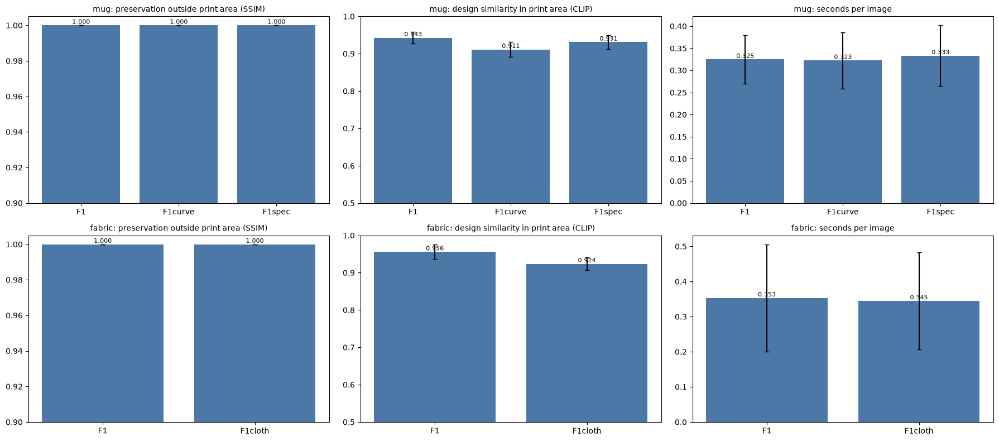

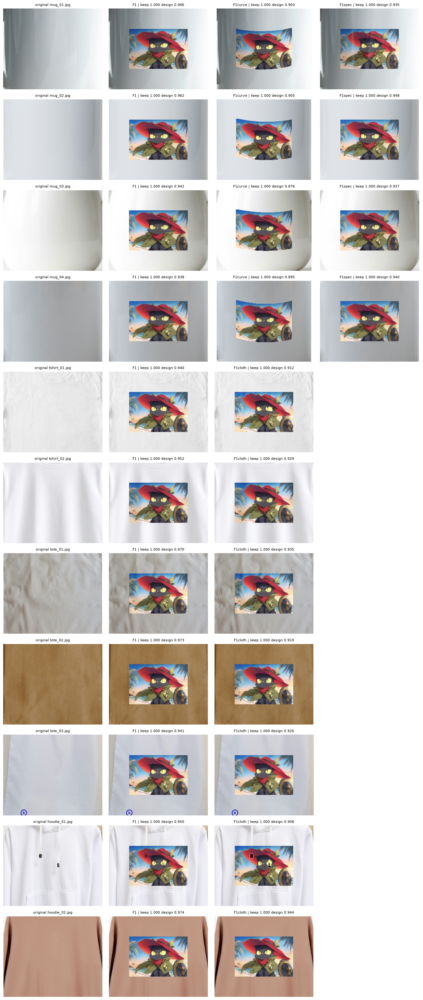

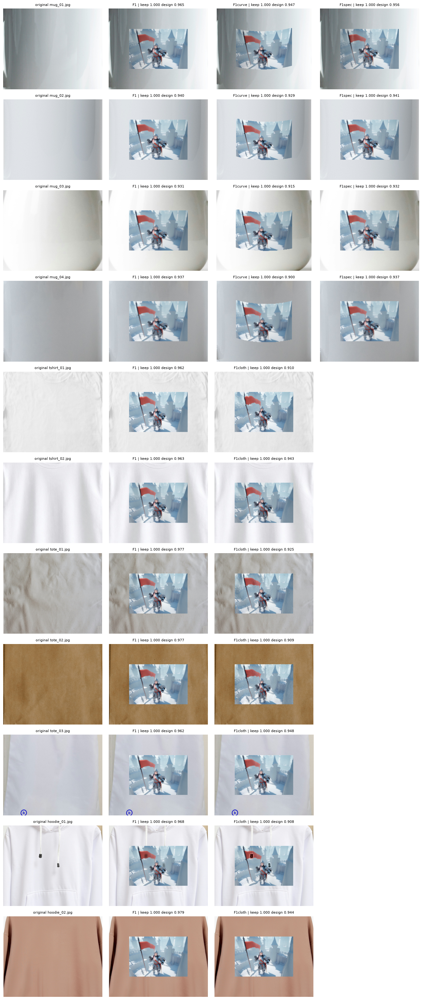

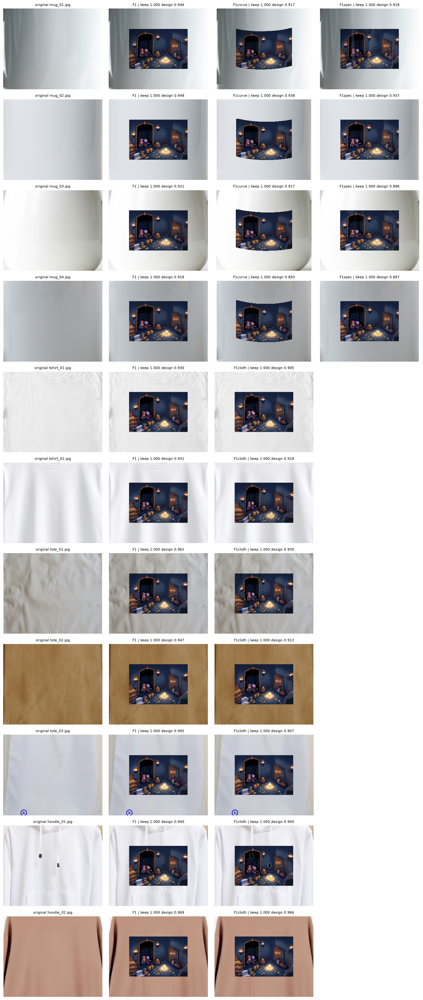

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for i, grp in enumerate(['mug', 'fabric']):
    ms = [m for m in METHODS if ((grp == 'mug') and 'mug' in CANDIDATES[m][0]) or ((grp == 'fabric') and set(FABRIC) & set(CANDIDATES[m][0]))]
    sub = summ.loc[grp].reindex(ms)
    for ax, col, title in zip(axes[i], ['keep_ssim', 'design_sim', 'sec'],
                              ['preservation outside print area (SSIM)', 'design similarity in print area (CLIP)', 'seconds per image']):
        ax.bar(range(len(ms)), sub[(col, 'mean')], yerr=sub[(col, 'std')].fillna(0), capsize=3, color='#4C78A8')
        for j, v in enumerate(sub[(col, 'mean')]):
            ax.text(j, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
        ax.set_xticks(range(len(ms)), ms)
        ax.set_title(f'{grp}: {title}', fontsize=10)
    axes[i, 0].set_ylim(0.9, 1.005)
    axes[i, 1].set_ylim(0.5, 1.0)
plt.tight_layout()
plt.savefig(OUT_DIR / 'f1m_scores.png', dpi=90)
plt.show()


def zoom(im, name, box_h=None):
    x, y, w, h = BOX[name]
    pad = int(0.35 * w)
    return im.crop((max(x - pad, 0), max(y - pad, 0), min(x + w + pad, im.width), min(y + (box_h or h) + pad, im.height)))


# 그림별 확대 비교: 행 = 굿즈, 열 = 원본 + 그 굿즈에 해당하는 후보
for game in DESIGNS:
    names = GOODS.file.tolist()
    ncol = 1 + max(sum(KIND[n] in CANDIDATES[m][0] for m in METHODS) for n in names)
    fig, axes = plt.subplots(len(names), ncol, figsize=(3.4 * ncol, 2.9 * len(names)), squeeze=False)
    for i, n in enumerate(names):
        axes[i, 0].imshow(zoom(load_goods(n), n))
        axes[i, 0].set_title(f'original {n}', fontsize=8)
        j = 1
        for m in METHODS:
            if KIND[n] not in CANDIDATES[m][0]:
                continue
            r = fs[(fs.goods == n) & (fs.design == game) & (fs.method == m)]
            if len(r):
                r = r.iloc[0]
                axes[i, j].imshow(zoom(Image.open(OUT_DIR / r.file), n, int(float(fr.set_index('file').box_h[r.file]))))
                axes[i, j].set_title(f'{m} | keep {r.keep_ssim:.3f} design {r.design_sim:.3f}', fontsize=8)
            else:
                axes[i, j].set_title(f'{m} | no image (see f1m_records.csv)', fontsize=8)
            j += 1
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'f1m_zoom_{game}.png', dpi=60)
    plt.show()